In [95]:
#F0484 Melbourne Housing Market - Price
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from data_analysis import summarize_categorical, summarize_numeric
import os

pd.set_option('display.width', 1000)
pd.set_option('display.max_columns', None)

filename = '../MELBOURNE_HOUSE_PRICES_LESS.csv'
df = pd.read_csv(filename)
categorical_col = df.select_dtypes(include=['object']).columns.tolist()
numeric_col = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

df = df.dropna(subset=['Price'])
#1. duplicate rows
print("Duplicate rows in df:", df.duplicated().sum())
df = df.drop_duplicates()

#4. Invalid values
print("df")
print("Price <= 50000:", (df['Price'] <= 50000).sum())
print("Rooms <= 0:", (df['Rooms'] <= 0).sum())
print("Distance < 0:", (df['Distance'] < 0).sum())
print("Propertycount < 0:", (df['Propertycount'] < 0).sum())

Duplicate rows in df: 1
df
Price <= 50000: 0
Rooms <= 0: 0
Distance < 0: 0
Propertycount < 0: 0


Dataset

In [96]:
#split into train, validation and test ds
rng = np.random.RandomState(42)
perm = rng.permutation(len(df)) #shuffle indices

train_split_index = int(0.8 * len(df))
validation_split_index = int(0.9 * len(df))

train_df = df.iloc[perm[:train_split_index]].copy() #select all of the indices up to split_ind and map them to real rows
validation_df = df.iloc[perm[train_split_index:validation_split_index]].copy()
test_df = df.iloc[perm[validation_split_index:]].copy()
print(f"Train:\n {train_df.head(5)}\nValidation:\n{validation_df.head(5)}\nTest: \n{test_df.head(5)}")

Train:
              Suburb            Address  Rooms Type      Price Method        SellerG        Date  Postcode                  Regionname  Propertycount  Distance                 CouncilArea
53971   Sandringham      3 Campbell St      3    h  1650000.0      S  hockingstuart  26/08/2017      3191       Southern Metropolitan           4497      15.2        Bayside City Council
49860       Mentone  3/121 Balcombe Rd      3    u   772500.0      S         Hodges  24/09/2016      3194  South-Eastern Metropolitan           6162      20.0       Kingston City Council
38183      Werribee       13 Carly Tce      3    h   572000.0      S         Benlor  19/05/2018      3030        Western Metropolitan          16166      14.7        Wyndham City Council
1578    Templestowe       25 Smiths Rd      4    h  1810000.0     SP         Jellis   1/09/2018      3106        Eastern Metropolitan           6202      15.5     Manningham City Council
8417   Airport West     32 Coniston Av      3    h   9700

In [97]:
num_test_sum = summarize_numeric(test_df[numeric_col])
cat_test_sum = summarize_categorical(test_df[categorical_col])
num_validation_sum = summarize_numeric(validation_df[numeric_col])
cat_validation_sum = summarize_categorical(validation_df[categorical_col])

In [98]:
print(f"Numerical test df: \n{num_test_sum}\n")
print(f"Categorical test df: \n{cat_test_sum}\n")

print(f"Numerical validation df: \n{num_validation_sum}\n")
print(f"Categorical validation df: \n{cat_validation_sum}\n")

Numerical test df: 
          column     N  % missing  cardinality       min        Q1    median         Q3        max           mean            std
0          Rooms  4844        0.0           10       1.0       2.0       3.0        4.0       16.0       3.064410       0.958342
1          Price  4844        0.0         1316  112000.0  615500.0  823750.0  1205000.0  6800000.0  997094.915979  599214.429557
2       Postcode  4844        0.0          186    3000.0    3051.0    3101.0     3163.0     3977.0    3121.981627     124.206416
3  Propertycount  4844        0.0          304     121.0    4242.0    6786.0    10412.0    21650.0    7582.053468    4446.505510
4       Distance  4844        0.0          150       0.0       7.0      11.7       17.2       47.4      12.747358       7.473417

Categorical test df: 
        column     N  % missing  cardinality                   mode  mode freq  mode %                   mode 2  mode 2 freq  mode 2 %
0       Suburb  4844        0.0          309    

In [99]:
#2. missing target values
# print(f"train_df count before: {len(train_df)}")
# train_df = train_df.dropna(subset=['Price'])
# print(f"train_df count after: {len(train_df)}")

# print(f"validation_df count before: {len(validation_df)}")
# validation_df = validation_df.dropna(subset=['Price'])
# print(f"validation_df count after: {len(validation_df)}")

# print(f"test_df count before: {len(test_df)}")
# test_df = test_df.dropna(subset=['Price'])
# print(f"test_df count after: {len(test_df)}")

In [100]:
#3. Outliers
Q1 = train_df['Price'].quantile(0.25)
Q3 = train_df['Price'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = train_df[(train_df['Price'] < lower) | (train_df['Price'] > upper)]
print("Lower bound:", lower)
print("Upper bound:", upper)
print("Number of outliers:", len(outliers))

train_df = train_df[(train_df['Price'] >= lower) & (train_df['Price'] <= upper)]

Lower bound: -272500.0
Upper bound: 2107500.0
Number of outliers: 1832


In [101]:
#5. High cardinality 
print("Regionname from test df")
avg_price_council = (train_df.groupby('Regionname')['Price'].mean().sort_values(ascending=False))
counter = 0
for council, price in avg_price_council.items():
    counter += 1
    print(f"{council} : ${price:,.2f}")
    if counter == 8: break

Regionname from test df
Southern Metropolitan : $1,120,266.67
Eastern Metropolitan : $1,034,548.45
South-Eastern Metropolitan : $831,097.83
Northern Metropolitan : $793,051.92
Western Metropolitan : $782,758.63
Eastern Victoria : $681,223.62
Northern Victoria : $639,565.04
Western Victoria : $415,015.10


In [102]:
print("CouncilArea from test df")
avg_price_council = (train_df.groupby('CouncilArea')['Price'].mean().sort_values(ascending=False))
counter = 0
for council, price in avg_price_council.items():
    counter += 1
    print(f"{council} : ${price:,.2f}")
    if counter == 8: break

CouncilArea from test df
Boroondara City Council : $1,245,386.23
Bayside City Council : $1,221,583.01
Manningham City Council : $1,163,529.08
Monash City Council : $1,122,666.09
Glen Eira City Council : $1,084,165.43
Stonnington City Council : $1,072,561.07
Whitehorse City Council : $1,066,573.60
Yarra City Council : $1,034,517.58


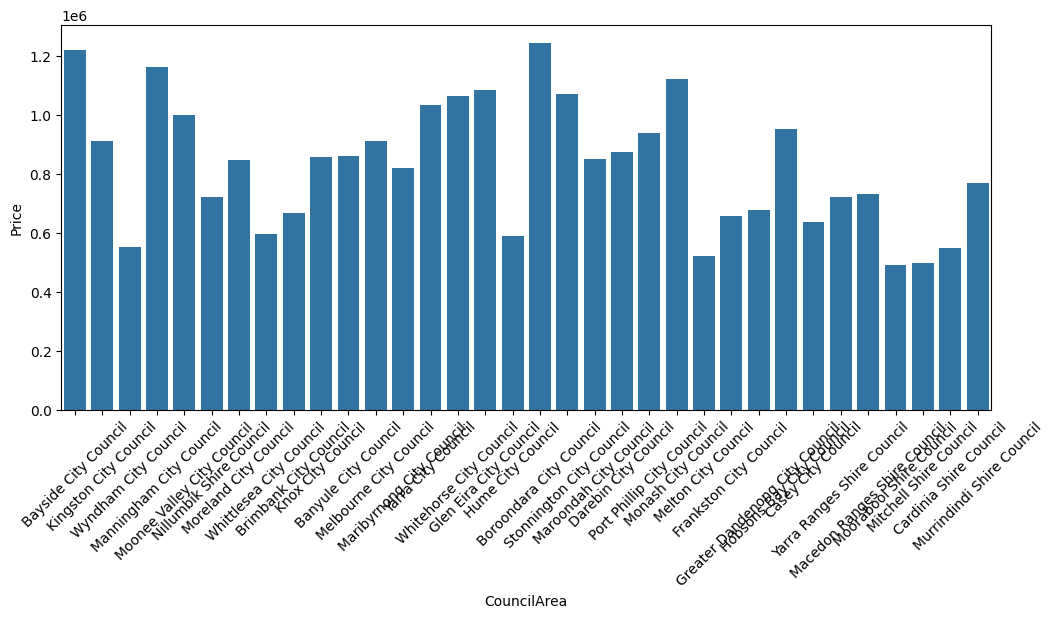

In [103]:
plt.figure(figsize=(12, 5))
sns.barplot(data=train_df, x='CouncilArea', y='Price', estimator='mean', errorbar=None)
plt.xticks(rotation=45)
plt.show()

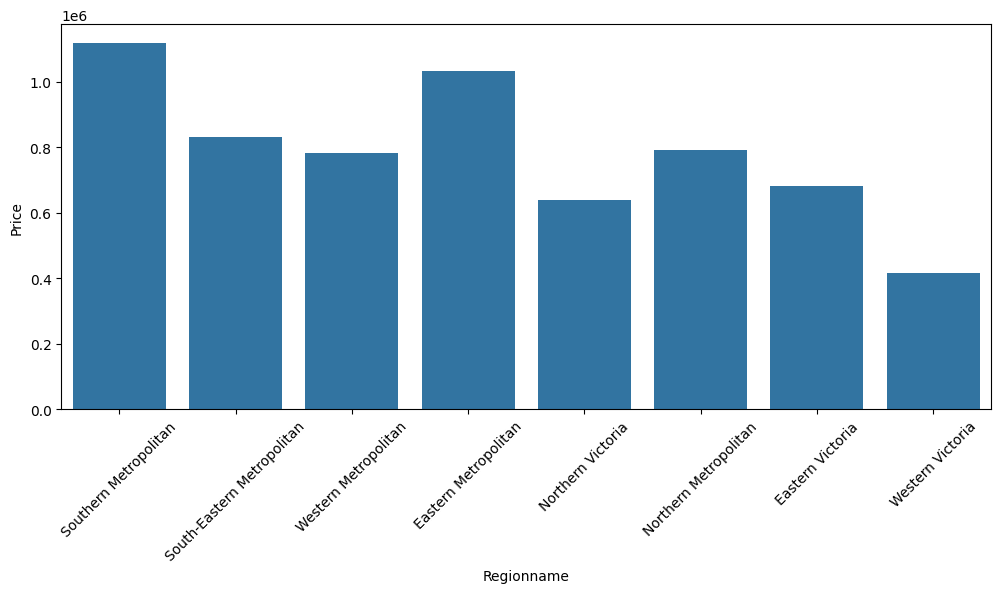

In [104]:
plt.figure(figsize=(12, 5))
sns.barplot(data=train_df, x='Regionname', y='Price', estimator='mean', errorbar=None)
plt.xticks(rotation=45)
plt.show()

In [105]:
top_councils = ['Boroondara City Council', 'Stonnington City Council', 'Bayside City Council']
train_df['CouncilArea'] = np.where(train_df['CouncilArea'].isin(top_councils), train_df['CouncilArea'], 'Other')
validation_df['CouncilArea'] = np.where(validation_df['CouncilArea'].isin(top_councils), validation_df['CouncilArea'], 'Other')
test_df['CouncilArea'] = np.where(test_df['CouncilArea'].isin(top_councils), test_df['CouncilArea'], 'Other')

top_regionname = ['Southern Metropolitan', 'Eastern Metropolitan', 'Western Victoria']
train_df['Regionname'] = np.where(train_df['Regionname'].isin(top_regionname), train_df['Regionname'], 'Other')
validation_df['Regionname'] = np.where(validation_df['Regionname'].isin(top_regionname), validation_df['Regionname'], 'Other')
test_df['Regionname'] = np.where(test_df['Regionname'].isin(top_regionname), test_df['Regionname'], 'Other')

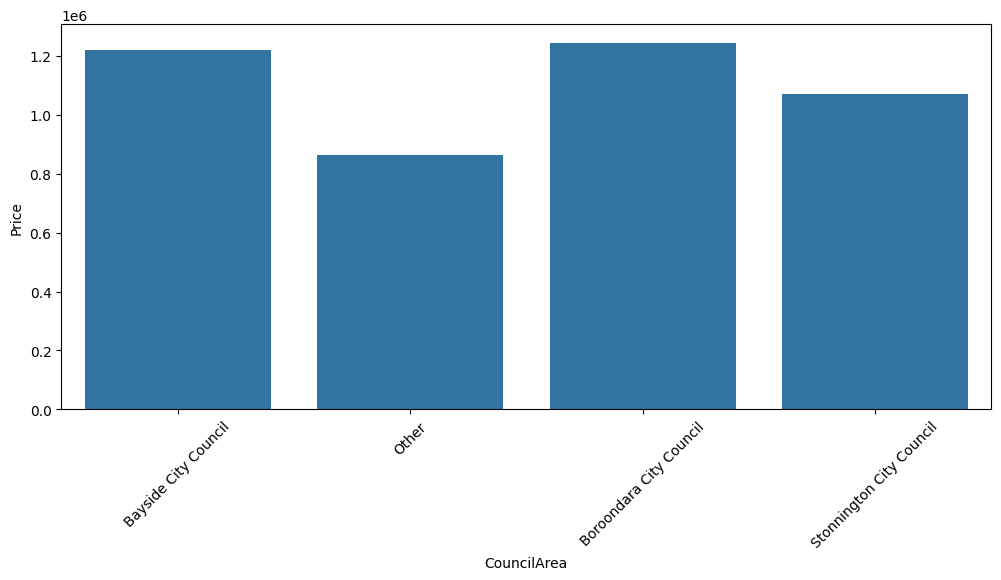

In [106]:
plt.figure(figsize=(12, 5))
sns.barplot(data=train_df, x='CouncilArea', y='Price', estimator='mean', errorbar=None)
plt.xticks(rotation=45)
plt.show()

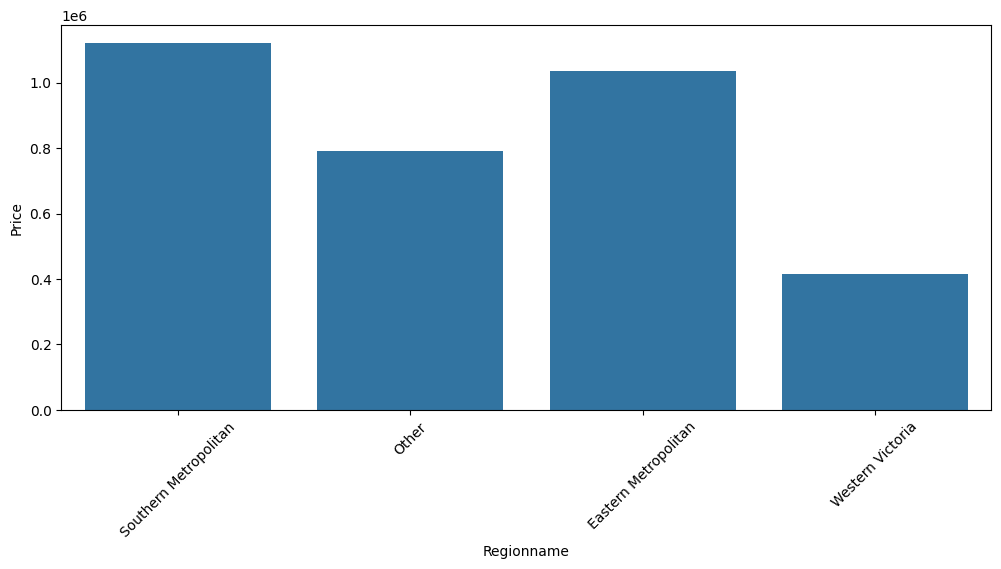

In [107]:
plt.figure(figsize=(12, 5))
sns.barplot(data=train_df, x='Regionname', y='Price', estimator='mean', errorbar=None)
plt.xticks(rotation=45)
plt.show()

In [108]:
categorical_cols = ['Type', 'Method', 'Regionname', 'CouncilArea']

In [109]:
#about councilarea i wouldn't drop them, just group according to top3 
columns_to_drop = ['Address', 'Suburb', 'SellerG', 'Postcode']
train_df = train_df.drop(columns=columns_to_drop)
validation_df = validation_df.drop(columns=columns_to_drop)

In [110]:
train_df['Date'] = pd.to_datetime(train_df['Date'], dayfirst=True)
train_df['Age'] = 2026 - train_df['Date'].dt.year
test_df['Date'] = pd.to_datetime(test_df['Date'], dayfirst=True)
test_df['Age'] = 2026 - test_df['Date'].dt.year
validation_df['Date'] = pd.to_datetime(validation_df['Date'], dayfirst=True)
validation_df['Age'] = 2026 - validation_df['Date'].dt.year
train_df = train_df.drop(columns=["Date"])
validation_df = validation_df.drop(columns=["Date"])
test_df = test_df.drop(columns=["Date"])

In [111]:
print(validation_df.iloc[0])
print(train_df.iloc[0])

Rooms                               4
Type                                h
Price                        825000.0
Method                             PI
Regionname       Eastern Metropolitan
Propertycount                   11925
Distance                         23.0
CouncilArea                     Other
Age                                 8
Name: 18168, dtype: object
Rooms                                3
Type                                 h
Price                        1650000.0
Method                               S
Regionname       Southern Metropolitan
Propertycount                     4497
Distance                          15.2
CouncilArea       Bayside City Council
Age                                  9
Name: 53971, dtype: object


Regression desicion tree

In [112]:
class Node:
    def __init__(self, feature=None, node_type=None, threshold=None, branches=None, value=None, probs=None, gini=0.0):
        self.feature = feature  #name of column to split on
        self.node_type = node_type  #'categorical', 'numeric', or 'leaf'
        self.threshold = threshold  #threshold float value fro numeric split
        self.branches = (branches if branches is not None else {})  #dict mapping branch key -> Node
        self.value = value  #leaf prediction value
        self.probs = probs if probs is not None else {}  # Class probability dict
        self.gini = gini #only for cdt

    def is_leaf(self):
        return self.value is not None


class CustomRegressionTree:
    def __init__(self, max_depth=5, min_samples_split=5, num_thresholds=5, max_features = None, categorical_cols=None, binary_cols=None, numeric_cols=None):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.num_thresholds = max(5, num_thresholds)
        self.max_features = max_features
        self.categorical_cols = categorical_cols or []
        self.binary_cols = binary_cols or []
        self.numeric_cols = numeric_cols or []
        self.root = None

    def _variance(self, y):
        if len(y) <= 1:
            return 0.0
        return np.sum((y - np.mean(y)) ** 2)

    def _evaluate_split(self, y_subsets): #calculate sum of squared errors
        total_sse = sum(self._variance(y_sub) for y_sub in y_subsets)
        return total_sse

    def _find_best_split(self, X, y): #goal - to minimize sse
        best_sse = float("inf")
        best_split = None
        parent_sse = self._variance(y)

        all_cols = list(X.columns)
        if self.max_features == "sqrt":
            num_cols = max(1, int(np.sqrt(len(all_cols))))
        elif isinstance(self.max_features, int):
            num_cols = max(1, min(self.max_features, len(all_cols)))
        elif (isinstance(self.max_features, float) and 0.0 < self.max_features <= 1.0):
            num_cols = max(1, int(self.max_features * len(all_cols)))
        else:
            num_cols = len(all_cols) 

        selected_cols = np.random.choice(all_cols, size=num_cols, replace=False)
        
        for col in selected_cols:
            if col in self.categorical_cols: #if column is categorical feature
                categories = X[col].unique() #get all of values in column without repetition
                if len(categories) <= 1:
                    continue

                subsets_y = [y[X[col] == cat] for cat in categories] #split y into n separate groups (lists of y corresponding to each category: [[prices_cat1],[prices_cat2],[prices_cat3]])
                current_sse = self._evaluate_split(subsets_y)

                if current_sse < best_sse:
                    best_sse = current_sse
                    best_split = {
                        "feature": col,
                        "node_type": "categorical",
                        "categories": categories,
                        "threshold": None,
                    }

            elif col in self.binary_cols:
                vals = X[col].unique()
                if len(vals) <= 1:
                    continue

                val1 = vals[0]
                subsets_y = [y[X[col] == val1], y[X[col] != val1]]
                current_sse = self._evaluate_split(subsets_y)

                if current_sse < best_sse:
                    best_sse = current_sse
                    best_split = {
                        "feature": col,
                        "node_type": "binary",
                        "categories": [val1, "other"],
                        "threshold": None,
                    }

            #here we need to find feature, which ater splitting produces the lowest variance in target variable, 
            #because if we split data into 2 branches where each branch has least deviation between the values, model would perform good
            elif col in self.numeric_cols: #numerical feature
                unique_vals = np.sort(X[col].unique())
                if len(unique_vals) <= 1:
                    continue

                percentiles = np.linspace(10, 90, self.num_thresholds) #generate percentile markers
                thresholds = np.percentile(X[col].dropna(), percentiles) #convert percentiles into values
                thresholds = np.unique(thresholds) 

                for thresh in thresholds:
                    left_mask = X[col] <= thresh
                    right_mask = ~left_mask

                    if not np.any(left_mask) or not np.any(right_mask):
                        continue

                    subsets_y = [y[left_mask], y[right_mask]]
                    current_sse = self._evaluate_split(subsets_y)

                    if current_sse < best_sse:
                        best_sse = current_sse
                        best_split = {
                            "feature": col,
                            "node_type": "numeric",
                            "threshold": thresh,
                            "categories": None,
                        }

        #return best split only if it improves variance
        if best_sse < parent_sse:
            return best_split
        return None

    def _build_tree(self, X, y, depth=0):
        num_samples = len(y)

        #stopping cond
        if (depth >= self.max_depth or num_samples < self.min_samples_split or self._variance(y) == 0):
            return Node(value=np.mean(y) if num_samples > 0 else 0.0)

        split = self._find_best_split(X, y)
        if split is None:
            return Node(value=np.mean(y))

        node = Node(feature=split["feature"], node_type=split["node_type"], threshold=split["threshold"])
        col = split["feature"]

        if split["node_type"] == "categorical":
            for cat in split["categories"]:
                child_X = X[X[col] == cat]
                child_y = y[X[col] == cat]
                node.branches[cat] = self._build_tree(child_X, child_y, depth + 1)

        elif split["node_type"] == "binary":
            target_val = split["categories"][0]
            mask = X[col] == target_val

            node.branches[target_val] = self._build_tree(X[mask], y[mask], depth + 1)
            node.branches["other"] = self._build_tree(X[~mask], y[~mask], depth + 1)

        elif split["node_type"] == "numeric":
            thresh = split["threshold"]
            left_mask = X[col] <= thresh

            node.branches["<= threshold"] = self._build_tree(X[left_mask], y[left_mask], depth + 1)
            node.branches["> threshold"] = self._build_tree(X[~left_mask], y[~left_mask], depth + 1)
        return node

    def fit(self, X, y):
        X_df = X.copy().reset_index(drop=True)
        y_ser = y.copy().reset_index(drop=True)

        self.root = self._build_tree(X_df, y_ser, depth=0)
        return self

    def _predict_single(self, row, node):
        if node.is_leaf():
            return node.value

        val = row[node.feature]

        if node.node_type == "categorical":
            if val in node.branches:
                return self._predict_single(row, node.branches[val])
            else:
                leaf_vals = [self._get_leaf_mean(b) for b in node.branches.values()]
                return np.mean(leaf_vals)

        elif node.node_type == "binary":
            target_val = list(node.branches.keys())[0]
            if val == target_val:
                return self._predict_single(row, node.branches[target_val])
            else:
                return self._predict_single(row, node.branches["other"])

        elif node.node_type == "numeric":
            if val <= node.threshold:
                return self._predict_single(row, node.branches["<= threshold"])
            else:
                return self._predict_single(row, node.branches["> threshold"])

    def _get_leaf_mean(self, node):
        if node.is_leaf():
            return node.value
        return np.mean([self._get_leaf_mean(b) for b in node.branches.values()])

    def predict(self, X):
        X_df = X.copy().reset_index(drop=True)
        return np.array([self._predict_single(row, self.root) for _, row in X_df.iterrows()])
  
    def plot_my_tree(self, max_depth=3):
        if self.root is None:
            raise ValueError("The tree has not been fitted. Call fit() first.")

        fig, ax = plt.subplots(figsize=(24, 12))

        nodes = []
        edges = []

        # Collect every node in the tree
        def collect(node, parent=None, label="", depth=0):
            node_id = len(nodes)
            nodes.append((node, node_id))

            if parent is not None:
                edges.append((parent, node_id, label))

            if node.is_leaf() or depth >= max_depth:
                return

            for key, child in node.branches.items():
                if node.node_type == "numeric":
                    if key == "<= threshold":
                        condition = f"<= {node.threshold:.2f}"
                    else:
                        condition = f"> {node.threshold:.2f}"
                else:
                    condition = str(key)

                collect(child, node_id, condition, depth + 1)

        collect(self.root)

        # Calculate each node's depth and position
        positions = {}
        leaf_counter = [0]

        
        def position_tree(node, depth=0):
            node_id = next(
                node_id for n, node_id in nodes if n is node
            )

            # Treat nodes at max_depth as terminal for visualization
            if node.is_leaf() or depth >= max_depth:
                x = leaf_counter[0]
                leaf_counter[0] += 1
            else:
                child_positions = [
                    position_tree(child, depth + 1)
                    for child in node.branches.values()
                ]
                x = sum(child_positions) / len(child_positions)

            positions[node_id] = (x, -depth)
            return x


        position_tree(self.root)

        # Draw edges and split conditions
        for parent, child, label in edges:
            x1, y1 = positions[parent]
            x2, y2 = positions[child]

            ax.plot([x1, x2], [y1, y2], color="gray", linewidth=0.8)

            ax.text(
                (x1 + x2) / 2,
                (y1 + y2) / 2,
                label,
                fontsize=7,
                ha="center",
                va="center",
                bbox=dict(facecolor="white", alpha=0.8, edgecolor="none")
            )

        # Draw all nodes
        for node, node_id in nodes:
            x, y = positions[node_id]

            if node.is_leaf():
                text = f"Price = {node.value:,.0f}"
                color = "lightgreen"
            elif node.node_type == "numeric":
                text = f"{node.feature}\n<= {node.threshold:.2f}?"
                color = "lightblue"
            else:
                text = f"{node.feature}\n({node.node_type})"
                color = "lightblue"

            ax.text(
                x, y, text,
                ha="center",
                va="center",
                fontsize=8,
                bbox=dict(
                    boxstyle="round,pad=0.4",
                    facecolor=color,
                    edgecolor="black"
                )
            )

        # Adjust figure size for large trees
        max_depth = max(-y for x, y in positions.values())
        num_leaves = leaf_counter[0]

        fig.set_size_inches(
            max(16, num_leaves * 1.5),
            max(8, (max_depth + 1) * 1.5)
        )

        ax.set_xlim(-1, max(1, num_leaves))
        ax.set_ylim(-max_depth - 1, 1)
        ax.axis("off")
        ax.set_title("Full Custom Regression Tree")

        plt.tight_layout()
        plt.show()

In [113]:
def evaluate_metrics(y_true, y_pred):
    '''{"MSE": mse, "MAE": mae, "MAPE (%)": mape, "R2": r2}'''
    mse = np.mean((y_true - y_pred) ** 2)
    mae = np.mean(np.abs(y_true - y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    ss_res = np.sum((y_true - y_pred) ** 2)  #residual sum of squares
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)  #total sum of squares
    r2 = 1 - (ss_res / ss_tot)

    return {"MSE": mse, "MAE": mae, "MAPE": mape, "R2": r2}

In [129]:
X_train_cust = train_df.drop(columns='Price')
y_train_cust = train_df["Price"]

X_validation_cust = validation_df.drop(columns=['Price'])
y_validation_cust = validation_df['Price']

X_test_cust = test_df.drop(columns='Price')
y_test_cust = test_df["Price"]

categorical_cols = ['Type', 'Method', 'Regionname', 'CouncilArea']
numerical_cols = ['Rooms', 'Propertycount', 'Distance', 'Age']

params_combinations = [
    {"max_depth": 3, "min_samples_split": 2, "num_thresholds": 5},
    {"max_depth": 5, "min_samples_split": 2, "num_thresholds": 5},
    {"max_depth": 8, "min_samples_split": 10, "num_thresholds": 10}, 
    {"max_depth": 12, "min_samples_split": 10, "num_thresholds": 10}, 
    {"max_depth": 1000, "min_samples_split": 2, "num_thresholds": 20}, 
]

performance = []
custom_reg_trees = []

for ind, comb in enumerate(params_combinations):
    max_depth, min_samples_split, num_thresholds = params_combinations[ind]["max_depth"], params_combinations[ind]["min_samples_split"], params_combinations[ind]["num_thresholds"]
    tree = CustomRegressionTree(max_depth, min_samples_split, num_thresholds, categorical_cols=categorical_cols, numeric_cols=numerical_cols)
    tree.fit(X_train_cust, y_train_cust)
    custom_reg_trees.append(tree)

    y_train_predictions = tree.predict(X_train_cust)
    train_performance = evaluate_metrics(y_train_cust, y_train_predictions)

    y_validation_predictions = tree.predict(X_validation_cust)
    validation_performance = evaluate_metrics(y_validation_cust, y_validation_predictions)

    performance.append(
        {
            "max_depth": comb["max_depth"],
            "min_samples_split": comb["min_samples_split"],
            "num_thresholds": comb["num_thresholds"],
            "Train_MAE": train_performance["MAE"],
            "Val_MAE": validation_performance["MAE"],
            "Train_MAPE": train_performance["MAPE"],
            "Val_MAPE": validation_performance["MAPE"],
            "Train_R2": train_performance["R2"],
            "Val_R2": validation_performance["R2"],
        }
    )

cust_results_df = pd.DataFrame(performance)
print(cust_results_df.to_string(index=False))


 max_depth  min_samples_split  num_thresholds     Train_MAE       Val_MAE  Train_MAPE  Val_MAPE  Train_R2   Val_R2
         3                  2               5 204021.800141 265838.222070   25.266652 26.234134  0.538881 0.411195
         5                  2               5 176675.901569 235026.511473   21.349229 22.553438  0.639818 0.502050
         8                 10              10 152508.613542 215244.051520   18.089731 20.180222  0.719584 0.542164
        12                 10              10 124818.398344 201452.549044   14.447822 18.234966  0.801397 0.563777
      1000                  2              20  96111.844072 202917.677465   10.814183 18.334695  0.858620 0.563101


In [ ]:
from sklearn.tree import DecisionTreeRegressor

X_train_sk = X_train_cust.copy() #make a copy of set for custom tree and apply encoding
X_validation_sk = X_validation_cust.copy()
X_test_sk = X_test_cust.copy()

X_train_sk = pd.get_dummies(X_train_sk, columns=categorical_cols, drop_first=False)
X_validation_sk = pd.get_dummies(X_validation_sk, columns=categorical_cols, drop_first=False).reindex(columns=X_train_sk.columns, fill_value=0)
X_test_sk = pd.get_dummies(X_test_sk, columns=categorical_cols, drop_first=False).reindex(columns=X_train_sk.columns, fill_value=0)

library_performance = []
library_trees = []

for ind, comb in enumerate(params_combinations):
    max_depth, min_samples_split = params_combinations[ind]["max_depth"], params_combinations[ind]["min_samples_split"]
    tree = DecisionTreeRegressor(max_depth=max_depth, min_samples_split=min_samples_split)
    tree.fit(X_train_sk, y_train_cust)
    
    library_trees.append(tree)

    y_test_predictions = tree.predict(X_test_sk)
    test_performance = evaluate_metrics(y_test_cust, y_test_predictions)

    y_validation_predictions = tree.predict(X_validation_sk)
    validation_performance = evaluate_metrics(y_validation_cust, y_validation_predictions)

    library_performance.append(
        {
            "max_depth": comb["max_depth"],
            "min_samples_split": comb["min_samples_split"],
            "Test_MAE": test_performance["MAE"],
            "Val_MAE": validation_performance["MAE"],
            "Test_MAPE": test_performance["MAPE"],
            "Val_MAPE": validation_performance["MAPE"],
            "Test_R2": test_performance["R2"],
            "Val_R2": validation_performance["R2"],
        }
    )

sklearn_results_df = pd.DataFrame(library_performance)
print(sklearn_results_df.to_string(index=False))

 max_depth  min_samples_split      Test_MAE       Val_MAE  Test_MAPE  Val_MAPE  Test_R2   Val_R2
         3                  2 293365.881899 294873.535679  29.578910 29.435643 0.355657 0.335916
         5                  2 248789.277319 249562.103840  24.184031 24.122522 0.487248 0.461329
         8                 10 219583.392620 221097.997518  20.916571 21.153858 0.572202 0.542457
        12                 10 202218.655630 204295.785945  18.536534 18.842633 0.598443 0.564339
      1000                  2 199918.172285 203948.820536  17.846571 18.386422 0.587085 0.558136


In [116]:
# comparison_df = pd.DataFrame()
# cust_cols = ['max_depth', 'min_samples_split', 'Train_MAE', 'Test_MAE', 'Val_MAE', 'Train_MAPE', 'Test_MAPE', 'Val_MAPE', 'Train_R2', 'Test_R2', 'Val_R2']  
# c_cols = cust_results_df.columns
# sklearn_cols = sklearn_results_df.columns
# for ind, col in enumerate(cust_cols):
#     if col in c_cols: comparison_df[col+'_cust'] = cust_results_df[col] 
#     if col in sklearn_cols: comparison_df[col+'_sklearn'] = sklearn_results_df[col]

# comparison_df.insert(2, 'num_thresholds_cust', cust_results_df['num_thresholds'])
# print(comparison_df)

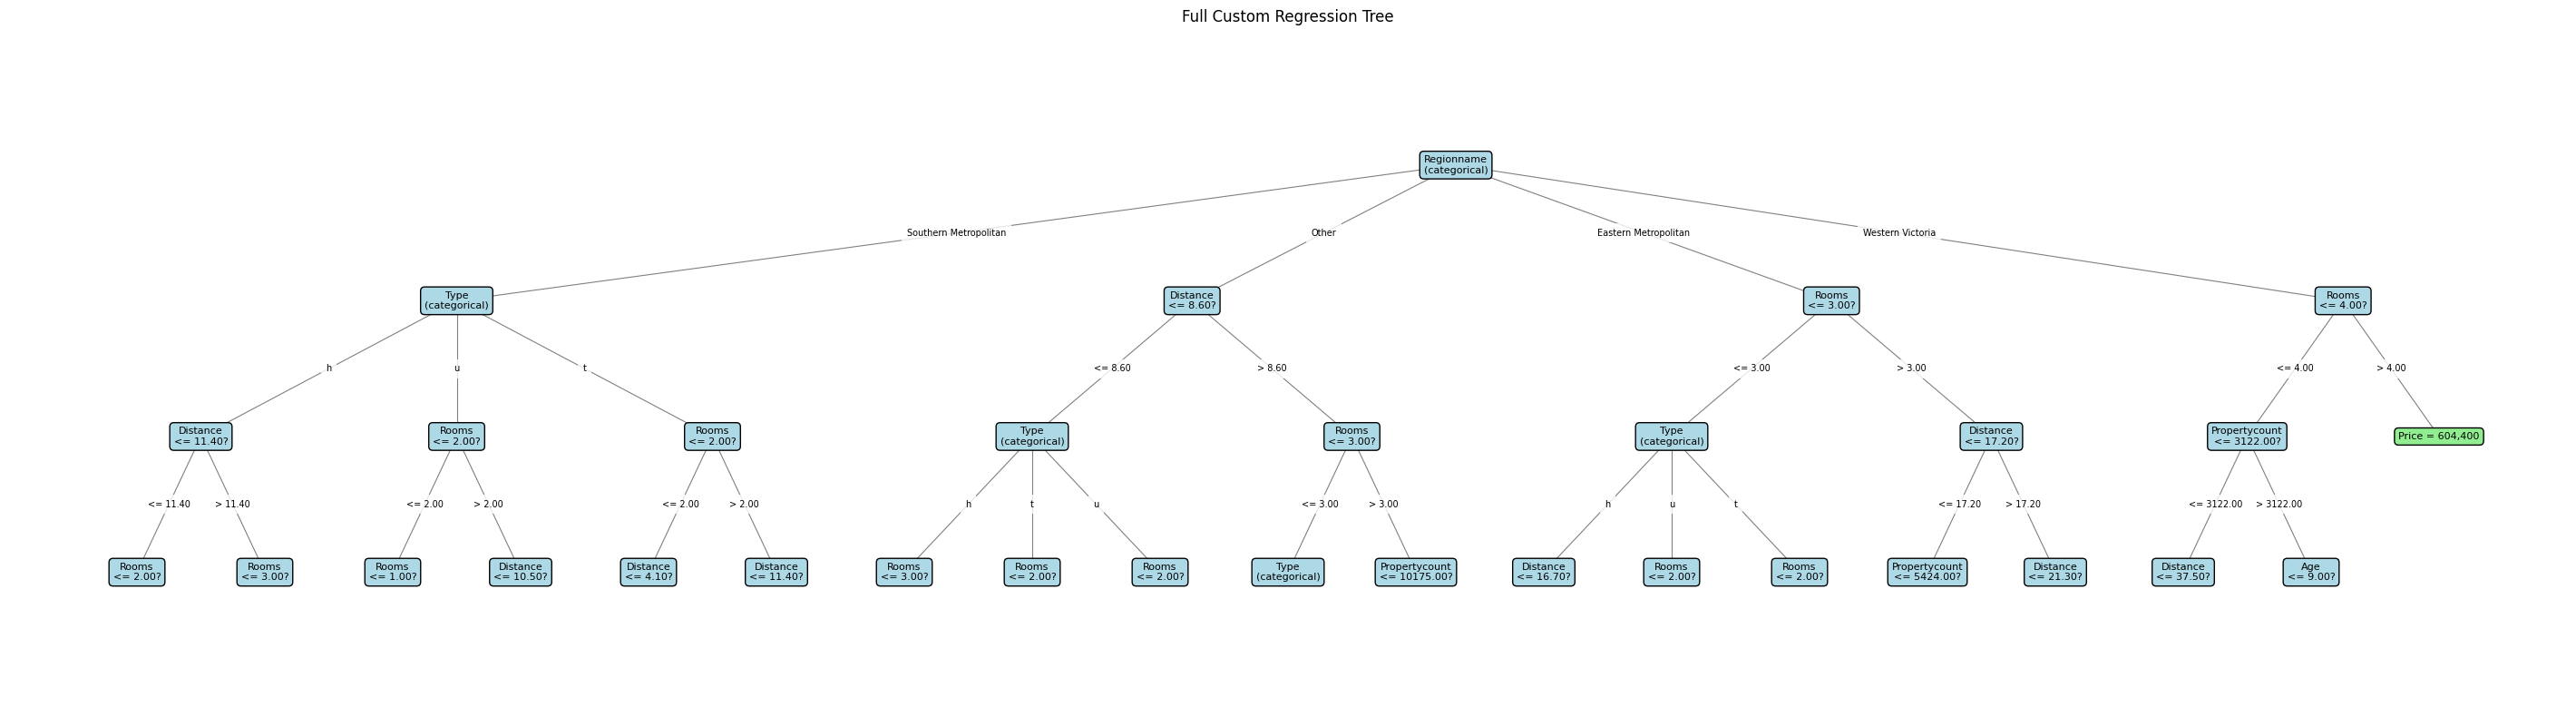

In [117]:
custom_reg_trees[3].plot_my_tree(max_depth=3)

Classification desicion tree

In [118]:
class CustomClassificationTree:
    """Classification Decision Tree supporting direct categorical, binary, and numeric splits."""

    def __init__(self,
        max_depth=5,
        min_samples_split=5,
        num_thresholds=5,
        criterion="gini",  # 'entropy' or 'gini'
        categorical_cols=None,
        binary_cols=None,
        numeric_cols=None,
    ):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.num_thresholds = max(5, num_thresholds)
        self.criterion = criterion #gini
        self.categorical_cols = categorical_cols or []
        self.binary_cols = binary_cols or []
        self.numeric_cols = numeric_cols or []
        self.root = None

    def _impurity(self, y):
        """Calculates Node Impurity using Entropy or Gini Index."""
        if len(y) <= 1:
            return 0.0

        _, counts = np.unique(y, return_counts=True)
        probabilities = counts / len(y)

        if self.criterion == "entropy":
            # Entropy: - sum(p * log2(p))
            return -np.sum(probabilities * np.log2(probabilities + 1e-9))
        else:
            # Gini Impurity: 1 - sum(p^2)
            return 1.0 - np.sum(probabilities**2)

    def _evaluate_split(self, parent_impurity, y_subsets):
        """Calculates Information Gain (Impurity Reduction)."""
        total_samples = sum(len(sub) for sub in y_subsets)
        if total_samples == 0:
            return 0.0

        weighted_child_impurity = sum((len(sub) / total_samples) * self._impurity(sub) for sub in y_subsets)

        # Information Gain = Parent Impurity - Weighted Child Impurity
        return parent_impurity - weighted_child_impurity

    def _get_mode(self, y):
        """Returns the most frequent class label in target series y."""
        if len(y) == 0:
            return None
        vals, counts = np.unique(y, return_counts=True)
        return vals[np.argmax(counts)]

    def _get_probs(self, y):
        """Returns a dictionary of class probabilities."""
        if len(y) == 0:
            return {}
        vals, counts = np.unique(y, return_counts=True)
        return {val: count / len(y) for val, count in zip(vals, counts)}

    def _find_best_split(self, X, y):
        """Iterates over features to find the split maximizing Information Gain."""
        best_gain = -1.0
        best_split = None
        parent_impurity = self._impurity(y)

        for col in X.columns:
            # --- 1. CATEGORICAL FEATURE (Multi-way Branching) ---
            if col in self.categorical_cols:
                categories = X[col].unique()
                if len(categories) <= 1:
                    continue

                subsets_y = [y[X[col] == cat] for cat in categories]
                current_gain = self._evaluate_split(parent_impurity, subsets_y)

                if current_gain > best_gain:
                    best_gain = current_gain
                    best_split = {
                        "feature": col,
                        "node_type": "categorical",
                        "categories": categories,
                        "threshold": None,
                    }

            # --- 2. BINARY FEATURE (Direct 2-way Branching) ---
            elif col in self.binary_cols:
                vals = X[col].unique()
                if len(vals) <= 1:
                    continue

                val1 = vals[0]
                subsets_y = [y[X[col] == val1], y[X[col] != val1]]
                current_gain = self._evaluate_split(parent_impurity, subsets_y)

                if current_gain > best_gain:
                    best_gain = current_gain
                    best_split = {
                        "feature": col,
                        "node_type": "binary",
                        "categories": [val1, "other"],
                        "threshold": None,
                    }

            # --- 3. NUMERICAL FEATURE (Tested against >= 5 thresholds) ---
            elif col in self.numeric_cols:
                unique_vals = np.sort(X[col].unique())
                if len(unique_vals) <= 1:
                    continue

                percentiles = np.linspace(10, 90, self.num_thresholds)
                thresholds = np.percentile(X[col].dropna(), percentiles)
                thresholds = np.unique(thresholds)

                for thresh in thresholds:
                    left_mask = X[col] <= thresh
                    right_mask = ~left_mask

                    if not np.any(left_mask) or not np.any(right_mask):
                        continue

                    subsets_y = [y[left_mask], y[right_mask]]
                    current_gain = self._evaluate_split(
                        parent_impurity, subsets_y
                    )

                    if current_gain > best_gain:
                        best_gain = current_gain
                        best_split = {
                            "feature": col,
                            "node_type": "numeric",
                            "threshold": thresh,
                            "categories": None,
                        }

        # Return best split only if it achieves positive Information Gain (> 0)
        if best_gain > 0:
            return best_split
        return None

    def _build_tree(self, X, y, depth=0):
        """Recursively builds classification tree branches."""
        num_samples = len(y)

        # Base Stopping Conditions -> Create Leaf Node
        if (
            depth >= self.max_depth
            or num_samples < self.min_samples_split
            or self._impurity(y) == 0
        ):
            return Node(value=self._get_mode(y), probs=self._get_probs(y), gini=self._impurity(y))

        split = self._find_best_split(X, y)
        if split is None:
            return Node(value=self._get_mode(y), probs=self._get_probs(y), gini=self._impurity(y))

        node = Node(
            feature=split["feature"],
            node_type=split["node_type"],
            threshold=split["threshold"],
            gini=self._impurity(y)
        )

        col = split["feature"]

        # Build Branches based on Node Type
        if split["node_type"] == "categorical":
            for cat in split["categories"]:
                child_X = X[X[col] == cat]
                child_y = y[X[col] == cat]
                node.branches[cat] = self._build_tree(
                    child_X, child_y, depth + 1
                )

        elif split["node_type"] == "binary":
            target_val = split["categories"][0]
            mask = X[col] == target_val

            node.branches[target_val] = self._build_tree(
                X[mask], y[mask], depth + 1
            )
            node.branches["other"] = self._build_tree(
                X[~mask], y[~mask], depth + 1
            )

        elif split["node_type"] == "numeric":
            thresh = split["threshold"]
            left_mask = X[col] <= thresh

            node.branches["<= threshold"] = self._build_tree(
                X[left_mask], y[left_mask], depth + 1
            )
            node.branches["> threshold"] = self._build_tree(
                X[~left_mask], y[~left_mask], depth + 1
            )

        return node

    def fit(self, X, y):
        """Fits classification decision tree model."""
        X_df = X.copy().reset_index(drop=True)
        y_ser = y.copy().reset_index(drop=True)

        self.root = self._build_tree(X_df, y_ser, depth=0)
        return self

    def _predict_single(self, row, node):
        """Traverses the tree to predict class label for a single row."""
        if node.is_leaf():
            return node.value

        val = row[node.feature]

        if node.node_type == "categorical":
            if val in node.branches:
                return self._predict_single(row, node.branches[val])
            else:
                # Fallback for unseen category: predict majority class from root/current node
                return node.value if node.value is not None else "Unknown"

        elif node.node_type == "binary":
            target_val = list(node.branches.keys())[0]
            if val == target_val:
                return self._predict_single(row, node.branches[target_val])
            else:
                return self._predict_single(row, node.branches["other"])

        elif node.node_type == "numeric":
            if val <= node.threshold:
                return self._predict_single(row, node.branches["<= threshold"])
            else:
                return self._predict_single(row, node.branches["> threshold"])

    def predict(self, X):
        """Predicts class labels for input DataFrame X."""
        X_df = X.copy().reset_index(drop=True)
        return np.array(
            [self._predict_single(row, self.root) for _, row in X_df.iterrows()]
        )

    def plot_my_tree(self, max_depth=3):
        import matplotlib.pyplot as plt

        if self.root is None:
            raise ValueError("The tree has not been fitted. Call fit() first.")

        fig, ax = plt.subplots(figsize=(24, 12))

        nodes = []
        edges = []

        # 1. Collect every node in the tree up to max_depth
        def collect(node, parent=None, label="", depth=0):
            node_id = len(nodes)
            nodes.append((node, node_id))

            if parent is not None:
                edges.append((parent, node_id, label))

            if node.is_leaf() or depth >= max_depth:
                return

            for key, child in node.branches.items():
                if node.node_type == "numeric":
                    if key == "<= threshold":
                        condition = f"<= {node.threshold:.2f}"
                    else:
                        condition = f"> {node.threshold:.2f}"
                else:
                    condition = str(key)

                collect(child, node_id, condition, depth + 1)

        collect(self.root)

        # 2. Calculate each node's depth and position
        positions = {}
        leaf_counter = [0]

        def position_tree(node, depth=0):
            # Find matching node_id safely from collected nodes
            node_id = next(
                (node_id for n, node_id in nodes if n is node), None
            )

            if node_id is None:
                return leaf_counter[0]

            # Stop recursing if leaf OR reached max_depth
            if node.is_leaf() or depth >= max_depth:
                x = leaf_counter[0]
                leaf_counter[0] += 1
            else:
                child_positions = [
                    position_tree(child, depth + 1)
                    for child in node.branches.values()
                ]
                x = sum(child_positions) / len(child_positions)

            positions[node_id] = (x, -depth)
            return x

        position_tree(self.root)

        # 3. Draw edges and split conditions
        for parent, child, label in edges:
            if parent in positions and child in positions:
                x1, y1 = positions[parent]
                x2, y2 = positions[child]

                ax.plot([x1, x2], [y1, y2], color="gray", linewidth=0.8)

                ax.text(
                    (x1 + x2) / 2,
                    (y1 + y2) / 2,
                    label,
                    fontsize=7,
                    ha="center",
                    va="center",
                    bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"),
                )

        # 4. Draw all nodes (handles both regression numbers and classification text)
        for node, node_id in nodes:
            if node_id not in positions:
                continue

            x, y = positions[node_id]
            gini_val = node.gini if node.gini is not None else 0.0
            gini_text = f"gini = {gini_val:.3f}"

            if node.is_leaf():
                if isinstance(node.value, (int, float)):
                    text = f"Price = ${node.value:,.0f}\n{gini_text}"
                else:
                    text = f"Class =\n{node.value}\n{gini_text}"
                color = "#b2ebd2"  # Mint green
            elif node.node_type == "numeric":
                text = f"{node.feature}\n<= {node.threshold:.2f}?\n{gini_text}"
                color = "#9ecae1"  # Light blue
            else:
                text = f"{node.feature}\n(Multi-way)\n{gini_text}"
                color = "#9ecae1"

            ax.text(x, y, text, ha="center", va="center", fontsize=8, bbox=dict(boxstyle="round,pad=0.4", facecolor=color, edgecolor="black"))

        # 5. Adjust figure size dynamically
        actual_max_depth = max((-y for x, y in positions.values()), default=1)
        num_leaves = max(leaf_counter[0], 1)

        fig.set_size_inches(
            max(16, num_leaves * 1.5), max(8, (actual_max_depth + 1) * 1.5)
        )

        ax.set_xlim(-1, max(1, num_leaves))
        ax.set_ylim(-actual_max_depth - 1, 1)
        ax.axis("off")
        ax.set_title("Custom Decision Tree Layout", fontsize=14, fontweight="bold")

        plt.tight_layout()
        plt.show()

In [130]:
ctrain_df = train_df.copy()
cvalidation_df = validation_df.copy()
ctest_df = test_df.copy()

labels = ['very small', 'small', 'medium', 'large', 'very large']
ctrain_df['Price_cat'], train_bins = pd.qcut(ctrain_df['Price'], q=5, labels=labels, retbins=True)
# 3. Apply the EXACT SAME training bin boundaries to validation set
cvalidation_df['Price_cat'] = pd.cut(cvalidation_df['Price'], bins=train_bins, labels=labels, include_lowest=True)
ctest_df['Price_cat'] = pd.cut(ctest_df['Price'], bins=train_bins, labels=labels, include_lowest=True)

ctrain_df = ctrain_df.drop(columns=['Price'])
cvalidation_df = cvalidation_df.drop(columns=['Price'])
ctest_df = ctest_df.drop(columns=['Price'])
ctrain_df.head(5)

,Rooms,Type,Method,Regionname,Propertycount,Distance,CouncilArea,Age,Price_cat
53971,3,h,S,Southern Metropolitan,4497,15.2,Bayside City Council,9,very large
49860,3,u,S,Other,6162,20.0,Other,10,medium
38183,3,h,S,Other,16166,14.7,Other,8,small
1578,4,h,SP,Eastern Metropolitan,6202,15.5,Other,8,very large
8417,3,h,S,Other,3464,10.4,Other,8,large


In [131]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
def evaluate_classification_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)

    # Get classification report as a dictionary
    report = classification_report(y_true, y_pred, output_dict=True, zero_division=0)

    # Extract macro-averaged precision, recall (sensitivity), and f1-score
    precision = report["macro avg"]["precision"]
    sensitivity = report["macro avg"]["recall"]  # Recall = Sensitivity
    f1 = report["macro avg"]["f1-score"]

    return {
        "Accuracy": acc,
        "Precision": precision,
        "Sensitivity": sensitivity,
        "F1-Score": f1,
    }

In [132]:
X_train_cust = ctrain_df.drop(columns=['Price_cat'])
y_train_cust = ctrain_df["Price_cat"].astype(str)
X_validation_cust = cvalidation_df.drop(columns=['Price_cat'])
y_validation_cust = cvalidation_df['Price_cat'].astype(str)
X_test_cust = ctest_df.drop(columns=['Price_cat'])
y_test_cust = ctest_df['Price_cat'].astype(str)

In [133]:
categorical_cols = ['Type', 'Method', 'Regionname', 'CouncilArea']
numerical_cols = ['Rooms', 'Propertycount', 'Distance', 'Age']

performance = []
custom_cls_trees = []

for ind, comb in enumerate(params_combinations):
    max_depth, min_samples_split, num_thresholds = params_combinations[ind]["max_depth"], params_combinations[ind]["min_samples_split"], params_combinations[ind]["num_thresholds"]
    tree = CustomClassificationTree(max_depth, min_samples_split, num_thresholds, categorical_cols=categorical_cols, numeric_cols=numerical_cols)
    tree.fit(X_train_cust, y_train_cust)
    custom_cls_trees.append(tree)

    y_train_predictions = tree.predict(X_train_cust)
    train_performance = evaluate_classification_metrics(y_train_cust, y_train_predictions)

    y_validation_predictions = tree.predict(X_validation_cust)
    validation_performance = evaluate_classification_metrics(y_validation_cust, y_validation_predictions)

    performance.append(
        {
            "max_depth": comb["max_depth"],
            "min_samples_split": comb["min_samples_split"],
            "num_thresholds": comb["num_thresholds"],
            "Train_Acc": train_performance["Accuracy"],
            "Val_Acc": validation_performance["Accuracy"],
            "Train_Precision": train_performance["Precision"],
            "Val_Precision": validation_performance["Precision"],
            "Train_Sensitivity": train_performance["Sensitivity"],
            "Val_Sensitivity": validation_performance["Sensitivity"],
            "Train_F1": train_performance["F1-Score"],
            "Val_F1": validation_performance["F1-Score"],
        }
    )

cust_results_df = pd.DataFrame(performance)
print(cust_results_df.to_string(index=False))

 max_depth  min_samples_split  num_thresholds  Train_Acc  Val_Acc  Train_Precision  Val_Precision  Train_Sensitivity  Val_Sensitivity  Train_F1   Val_F1
         3                  2               5   0.438165 0.423291         0.476185       0.374388           0.438120         0.367259  0.428526 0.349692
         5                  2               5   0.494243 0.479455         0.500032       0.391930           0.494382         0.416647  0.481484 0.393324
         8                 10              10   0.565546 0.508982         0.583202       0.367908           0.566126         0.380694  0.570034 0.372220
        12                 10              10   0.648904 0.526120         0.658909       0.382980           0.649462         0.394105  0.652517 0.386929
      1000                  2              20   0.736326 0.534586         0.743545       0.391142           0.736457         0.400426  0.738715 0.394381


In [134]:
best_tree = custom_cls_trees[3]

# Predict on Train and Validation
y_train_pred_best = best_tree.predict(X_train_cust)
y_val_pred_best = best_tree.predict(X_validation_cust)

labels = ["very small", "small", "medium", "large", "very large"]

# 1. Training Confusion Matrix
train_cm = confusion_matrix(
    y_train_cust, y_train_pred_best, labels=labels
)
train_cm_df = pd.DataFrame(
    train_cm,
    index=[f"Actual_{l}" for l in labels],
    columns=[f"Pred_{l}" for l in labels],
)

print("Training confusion matrix")
print(train_cm_df)

# 2. Validation Confusion Matrix
val_cm = confusion_matrix(
    y_validation_cust, y_val_pred_best, labels=labels
)
val_cm_df = pd.DataFrame(
    val_cm,
    index=[f"Actual_{l}" for l in labels],
    columns=[f"Pred_{l}" for l in labels],
)

print("Validation confusion matrix")
print(val_cm_df)

Training confusion matrix
                   Pred_very small  Pred_small  Pred_medium  Pred_large  Pred_very large
Actual_very small             5278        1629          337         139               12
Actual_small                   979        4683         1243         452               26
Actual_medium                  220        1470         3959        1522              205
Actual_large                    50         489         1107        4778             1167
Actual_very large               14         145          284        1470             5255
Validation confusion matrix
                   Pred_very small  Pred_small  Pred_medium  Pred_large  Pred_very large
Actual_very small              596         229           60          26                0
Actual_small                   137         506          200          84                3
Actual_medium                   29         242          356         211               22
Actual_large                    14          73          

In [ ]:
from sklearn.tree import DecisionTreeClassifier

cols_to_drop = ['Address', 'Suburb', 'SellerG', 'Postcode']
X_train_sk = X_train_cust.copy()
X_test_sk = X_test_cust.copy().drop(columns=cols_to_drop, errors='ignore').copy()
X_validation_sk = X_validation_cust.copy()

X_train_sk = pd.get_dummies(X_train_sk, columns=categorical_cols, drop_first=False)
X_validation_sk = pd.get_dummies(X_validation_sk, columns=categorical_cols, drop_first=False).reindex(columns=X_train_sk.columns, fill_value=0)
X_test_sk = pd.get_dummies(X_test_sk, columns=categorical_cols, drop_first=False).reindex(columns=X_train_sk.columns, fill_value=0)

library_performance = []
library_trees = []

for ind, comb in enumerate(params_combinations):
    max_depth, min_samples_split = params_combinations[ind]["max_depth"], params_combinations[ind]["min_samples_split"]
    tree = DecisionTreeClassifier(max_depth=max_depth, min_samples_split=min_samples_split)
    tree.fit(X_train_sk, y_train_cust)
    
    library_trees.append(tree)

    y_test_predictions = tree.predict(X_test_sk)
    test_performance = evaluate_classification_metrics(y_test_cust, y_test_predictions)

    y_validation_predictions = tree.predict(X_validation_sk)
    validation_performance = evaluate_classification_metrics(y_validation_cust, y_validation_predictions)

    library_performance.append(
        {
            "max_depth": comb["max_depth"],
            "min_samples_split": comb["min_samples_split"],
            "num_thresholds": comb["num_thresholds"],
            "Test_Acc": test_performance["Accuracy"],
            "Val_Acc": validation_performance["Accuracy"],
            "Test_Precision": test_performance["Precision"],
            "Val_Precision": validation_performance["Precision"],
            "Test_Sensitivity": test_performance["Sensitivity"],
            "Val_Sensitivity": validation_performance["Sensitivity"],
            "Test_F1": test_performance["F1-Score"],
            "Val_F1": validation_performance["F1-Score"],
        }
    )

sklearn_results_df = pd.DataFrame(library_performance)
print(sklearn_results_df.to_string(index=False))

 max_depth  min_samples_split  num_thresholds  Test_Acc  Val_Acc  Test_Precision  Val_Precision  Test_Sensitivity  Val_Sensitivity  Test_F1   Val_F1
         3                  2               5  0.394509 0.404708        0.300757       0.304504          0.346595         0.348589 0.300658 0.304641
         5                  2               5  0.444261 0.456948        0.368240       0.376738          0.392550         0.398698 0.376274 0.385084
         8                 10              10  0.493600 0.504026        0.422600       0.428243          0.435194         0.438829 0.418647 0.426066
        12                 10              10  0.542320 0.538509        0.454800       0.451685          0.477809         0.470392 0.463645 0.459228
      1000                  2              20  0.538604 0.543671        0.454004       0.459205          0.474046         0.475114 0.462406 0.465670


In [125]:
# comparison_df = pd.DataFrame()
# cust_cols = sklearn_results_df.columns 
# for ind, col in enumerate(cust_cols):
#     comparison_df[col+'_cust'] = cust_results_df[col] 
#     comparison_df[col+'_sklearn'] = sklearn_results_df[col]
#     if ind == 1: comparison_df['num_thresholds_cust'] = cust_results_df['num_thresholds']
# print(comparison_df)

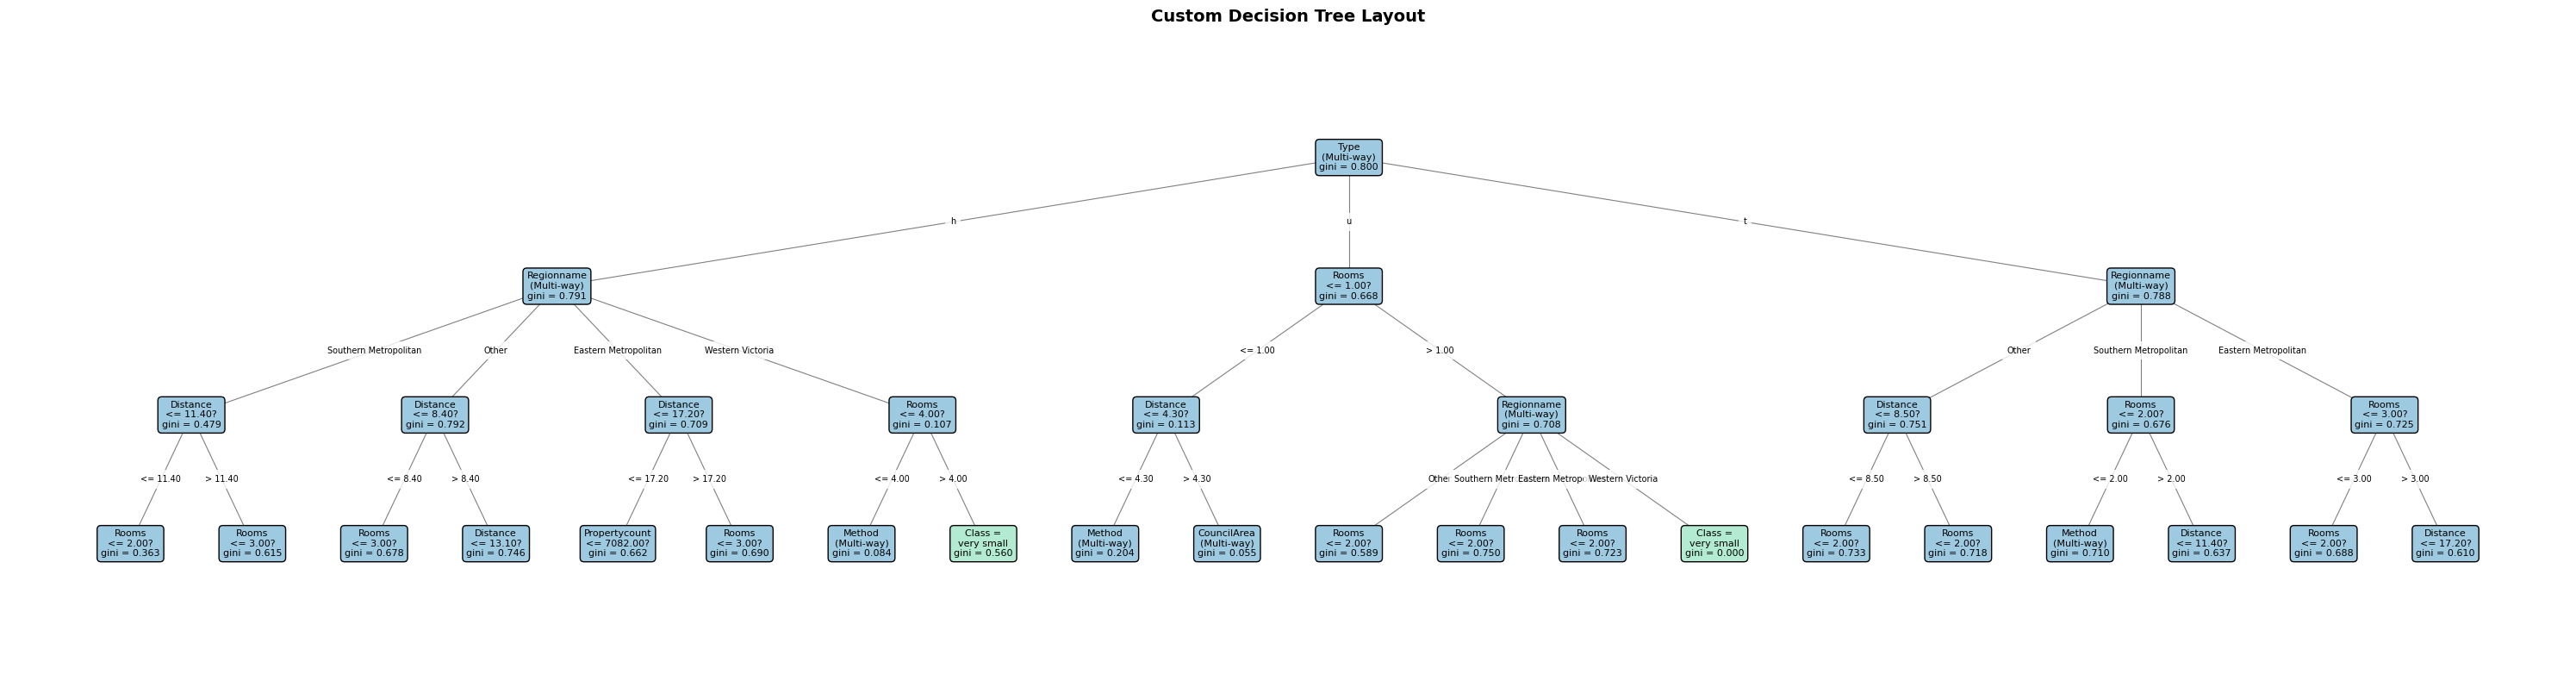

In [126]:
best_tree.plot_my_tree(max_depth=3)

4. Regression random forest

In [137]:
class CustomRandomForestRegressor:
    """Random Forest Regressor wrapping CustomRegressionTree instances with Bagging and Feature Subsampling."""

    def __init__(
        self,
        n_estimators=10,
        max_depth=8,
        min_samples_split=5,
        num_thresholds=5,
        max_features="sqrt",
        categorical_cols=None,
        binary_cols=None,
        numeric_cols=None,
    ):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.num_thresholds = num_thresholds
        self.max_features = max_features  # STORE IT
        self.categorical_cols = categorical_cols or []
        self.binary_cols = binary_cols or []
        self.numeric_cols = numeric_cols or []
        self.trees = []

    def _bootstrap_sample(self, X, y):
        """Generates a random bootstrap sample with replacement."""
        n_samples = len(X)
        indices = np.random.choice(n_samples, size=n_samples, replace=True)
        return X.iloc[indices].reset_index(drop=True), y.iloc[
            indices
        ].reset_index(drop=True)

    def fit(self, X, y):
        """Fits n_estimators individual regression trees on bootstrap samples."""
        self.trees = []
        X_df = X.copy().reset_index(drop=True)
        y_ser = y.copy().reset_index(drop=True)

        for i in range(self.n_estimators):
            X_sample, y_sample = self._bootstrap_sample(X_df, y_ser)

            # 2. PASS max_features down to CustomRegressionTree
            tree = CustomRegressionTree(
                max_depth=self.max_depth,
                min_samples_split=self.min_samples_split,
                num_thresholds=self.num_thresholds,
                max_features=self.max_features,  # PASSED HERE
                categorical_cols=self.categorical_cols,
                binary_cols=self.binary_cols,
                numeric_cols=self.numeric_cols,
            )

            tree.fit(X_sample, y_sample)
            self.trees.append(tree)

        print(
            f"Successfully trained Random Forest with {self.n_estimators} trees, max_depth: {self.max_depth}, min_samples_split: {min_samples_split} ! 🌲"
        )
        return self

    def predict(self, X):
        """Predicts continuous target values by averaging predictions across all trees."""
        X_df = X.copy().reset_index(drop=True)

        # Collect predictions from each tree: shape -> (n_estimators, n_samples)
        tree_predictions = np.array([tree.predict(X_df) for tree in self.trees])

        # Average across columns (axis=0) for regression ensemble output
        return np.mean(tree_predictions, axis=0)

In [138]:
from sklearn.model_selection import KFold

X_test_cust = train_df.drop(columns='Price')
y_test_cust = train_df["Price"]
X_validation_cust = validation_df.drop(columns=['Price'])
y_validation_cust = validation_df['Price']
X_values = (pd.concat([X_test_cust, X_validation_cust], axis=0).reset_index(drop=True))
y_values = (pd.concat([y_test_cust, y_validation_cust], axis=0).reset_index(drop=True))

n_estimators_list = [3, 5, 10]
max_depth_list = [3, 5, 8]
min_samples_split_list = [5, 10, 15]

kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = []

# 3. Perform 5-Fold Cross-Validation across all 27 combinations
for n_trees in n_estimators_list:
    for depth in max_depth_list:
        for min_split in min_samples_split_list:
            fold_maes = []
            fold_r2s = []

            for train_idx, val_idx in kf.split(X_values):
                X_tr, y_tr = X_values.iloc[train_idx], y_values.iloc[train_idx]
                X_va, y_va = X_values.iloc[val_idx], y_values.iloc[val_idx]

                # Train Custom Random Forest
                rf = CustomRandomForestRegressor(
                    n_estimators=n_trees,
                    max_depth=depth,
                    min_samples_split=min_split,
                    num_thresholds=5,
                    categorical_cols=categorical_cols,
                    numeric_cols=numerical_cols,
                )
                rf.fit(X_tr, y_tr)

                preds = rf.predict(X_va)
                current_metrics = evaluate_metrics(y_va, preds)
                fold_maes.append(current_metrics['MAE'])
                fold_r2s.append(current_metrics['R2'])

            cv_results.append(
                {
                    "n_estimators": n_trees,
                    "max_depth": depth,
                    "min_samples_split": min_split,
                    "Mean_CV_MAE": np.mean(fold_maes),
                    "Std_CV_MAE": np.std(fold_maes),
                    "Mean_CV_R2": np.mean(fold_r2s),
                    "Std_CV_R2": np.std(fold_r2s),
                    "fold_r2_scores": fold_r2s,
                }
            )

df_cv_results = pd.DataFrame(cv_results)
print(df_cv_results.to_string(index=False))

Successfully trained Random Forest with 3 trees, max_depth: 3, min_samples_split: 2 ! 🌲
Successfully trained Random Forest with 3 trees, max_depth: 3, min_samples_split: 2 ! 🌲
Successfully trained Random Forest with 3 trees, max_depth: 3, min_samples_split: 2 ! 🌲
Successfully trained Random Forest with 3 trees, max_depth: 3, min_samples_split: 2 ! 🌲
Successfully trained Random Forest with 3 trees, max_depth: 3, min_samples_split: 2 ! 🌲
Successfully trained Random Forest with 3 trees, max_depth: 3, min_samples_split: 2 ! 🌲
Successfully trained Random Forest with 3 trees, max_depth: 3, min_samples_split: 2 ! 🌲
Successfully trained Random Forest with 3 trees, max_depth: 3, min_samples_split: 2 ! 🌲
Successfully trained Random Forest with 3 trees, max_depth: 3, min_samples_split: 2 ! 🌲
Successfully trained Random Forest with 3 trees, max_depth: 3, min_samples_split: 2 ! 🌲
Successfully trained Random Forest with 3 trees, max_depth: 3, min_samples_split: 2 ! 🌲
Successfully trained Random Fore

In [148]:
print("Top custom conf")
print(df_cv_results.sort_values("Mean_CV_MAE", ascending=True).head(5))

Top custom conf
    n_estimators  max_depth  min_samples_split    Mean_CV_MAE   Std_CV_MAE  Mean_CV_R2  Std_CV_R2                                     fold_r2_scores
16             5          8                 10  185844.745668  4160.753088    0.608239   0.016783  [0.6017416780118738, 0.6146542694387204, 0.617...
17             5          8                 15  187149.645575  4818.588360    0.605114   0.023245  [0.5814349763460962, 0.5946225989961066, 0.647...
26            10          8                 15  187193.025975  1205.963085    0.607508   0.011174  [0.596408925537455, 0.6092727867542465, 0.6268...
24            10          8                  5  188378.500684  3978.664809    0.603813   0.021431  [0.5862503636758096, 0.5907054462696995, 0.645...
15             5          8                  5  189492.489943  6111.816131    0.597792   0.026625  [0.5479061704352524, 0.5931471963671038, 0.618...


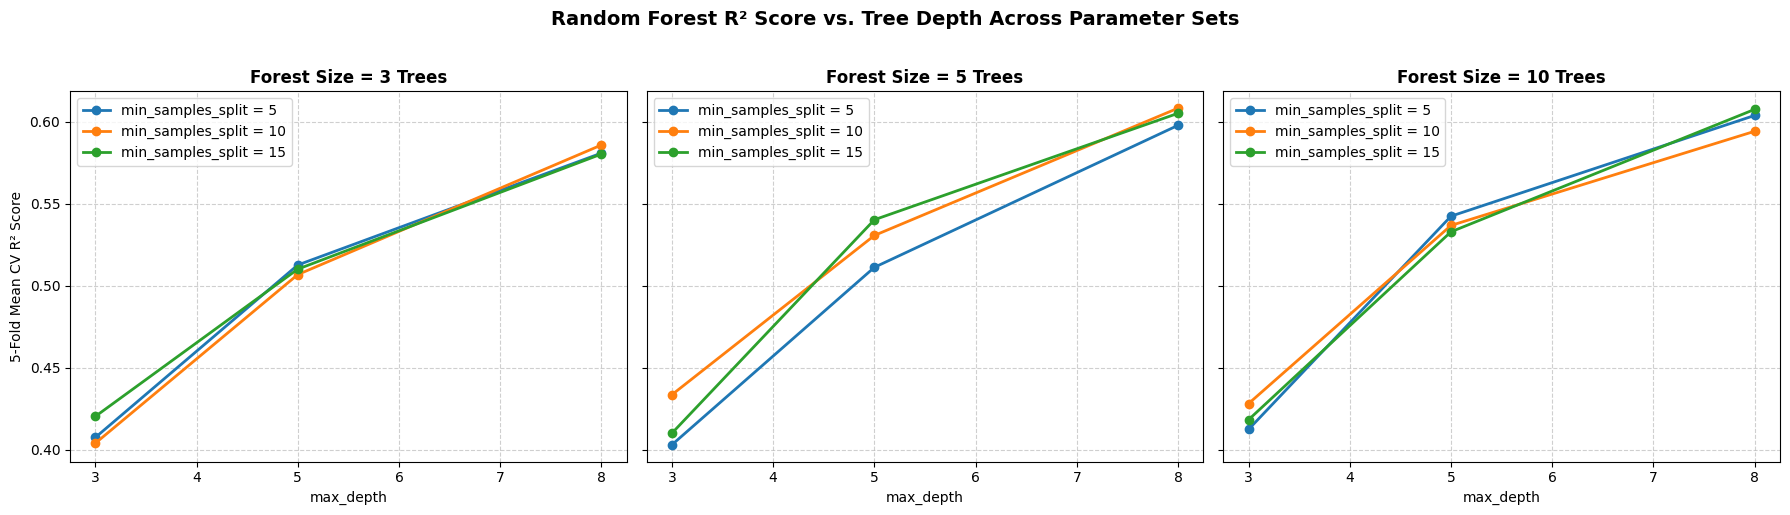

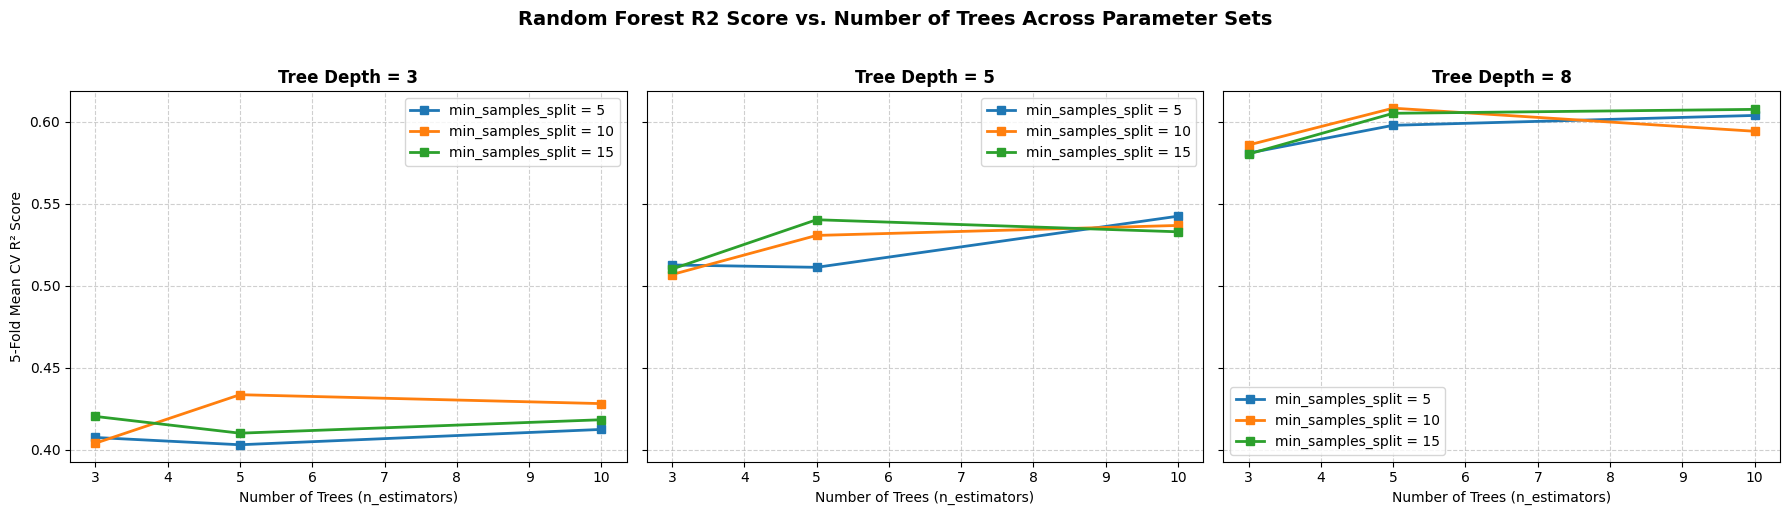

In [140]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
colors = {5: "#1f77b4", 10: "#ff7f0e", 15: "#2ca02c"}

for idx, n_trees in enumerate(n_estimators_list):
    ax = axes[idx]
    df_trees = df_cv_results[df_cv_results["n_estimators"] == n_trees]

    for min_split in min_samples_split_list:
        df_sub = df_trees[df_trees["min_samples_split"] == min_split]
        ax.plot(
            df_sub["max_depth"],
            df_sub["Mean_CV_R2"],
            marker="o",
            linewidth=2,
            label=f"min_samples_split = {min_split}",
            color=colors[min_split],
        )

    ax.set_title(f"Forest Size = {n_trees} Trees", fontsize=12, fontweight="bold")
    ax.set_xlabel("max_depth", fontsize=10)
    if idx == 0:
        ax.set_ylabel("5-Fold Mean CV R² Score", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend()

plt.suptitle(
    "Random Forest R² Score vs. Tree Depth Across Parameter Sets",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for idx, depth in enumerate([3, 5, 8]):
    ax = axes[idx]
    df_depth = df_cv_results[df_cv_results["max_depth"] == depth]

    for min_split in [5, 10, 15]:
        df_sub = df_depth[df_depth["min_samples_split"] == min_split]
        ax.plot(
            df_sub["n_estimators"],
            df_sub["Mean_CV_R2"],
            marker="s",
            linewidth=2,
            label=f"min_samples_split = {min_split}",
            color=colors[min_split],
        )

    ax.set_title(f"Tree Depth = {depth}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Number of Trees (n_estimators)", fontsize=10)
    if idx == 0:
        ax.set_ylabel("5-Fold Mean CV R² Score", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend()

plt.suptitle("Random Forest R2 Score vs. Number of Trees Across Parameter Sets",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

Starting 5-Fold Cross-Validation using Scikit-Learn RandomForestRegressor...

=== SCIKIT-LEARN TOP 5 PERFORMING CONFIGURATIONS ===
 n_estimators  max_depth  min_samples_split   Mean_CV_MAE  Std_CV_MAE  Mean_CV_R2  Std_CV_R2
           10          8                 15 180749.810541 1467.711927    0.627221   0.012608
           10          8                  5 181034.521837 2741.216024    0.625955   0.017510
           10          8                 10 182192.523469 2273.650640    0.622129   0.017197
            5          8                 15 183934.420119 2975.195617    0.617047   0.017602
            5          8                  5 183716.809216 2552.551315    0.616396   0.015988
Top custom conf
    n_estimators  max_depth  min_samples_split    Mean_CV_MAE   Std_CV_MAE  Mean_CV_R2  Std_CV_R2                                     fold_r2_scores
16             5          8                 10  185844.745668  4160.753088    0.608239   0.016783  [0.6017416780118738, 0.6146542694387204, 0.617.

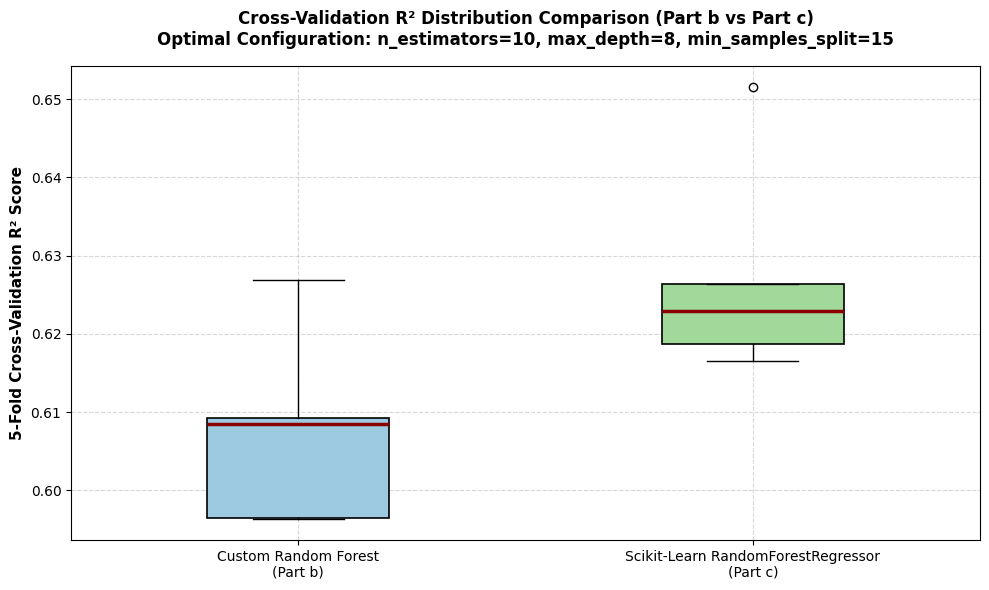

In [141]:
from sklearn.ensemble import RandomForestRegressor

X_cv_raw = pd.concat([X_test_cust, X_validation_cust], axis=0).reset_index(drop=True)
y_cv = (pd.concat([y_test_cust, y_validation_cust], axis=0).reset_index(drop=True).astype(float))
X_cv_sklearn = pd.get_dummies(X_cv_raw, drop_first=True)

n_estimators_list = [3, 5, 10]
max_depth_list = [3, 5, 8]
min_samples_split_list = [5, 10, 15]

kf = KFold(n_splits=5, shuffle=True, random_state=42)
sklearn_cv_results = []

print("Starting 5-Fold Cross-Validation using Scikit-Learn RandomForestRegressor...")

# ==============================================================================
# 3. SCIKIT-LEARN CROSS-VALIDATION LOOP
# ==============================================================================
for n_trees in n_estimators_list:
    for depth in max_depth_list:
        for min_split in min_samples_split_list:
            fold_maes = []
            fold_r2s = []

            for train_idx, val_idx in kf.split(X_cv_sklearn):
                X_tr, y_tr = (
                    X_cv_sklearn.iloc[train_idx],
                    y_cv.iloc[train_idx],
                )
                X_va, y_va = X_cv_sklearn.iloc[val_idx], y_cv.iloc[val_idx]

                rf_sk = RandomForestRegressor(
                    n_estimators=n_trees,
                    max_depth=depth,
                    min_samples_split=min_split,
                    max_features="sqrt",
                    random_state=42,
                    n_jobs=-1,  # Parallel execution across CPU cores
                )
                rf_sk.fit(X_tr, y_tr)

                preds = rf_sk.predict(X_va)
                metrics = evaluate_metrics(y_va, preds)
                fold_maes.append(metrics["MAE"])
                fold_r2s.append(metrics["R2"])

            sklearn_cv_results.append(
                {
                    "n_estimators": n_trees,
                    "max_depth": depth,
                    "min_samples_split": min_split,
                    "Mean_CV_MAE": np.mean(fold_maes),
                    "Std_CV_MAE": np.std(fold_maes),
                    "Mean_CV_R2": np.mean(fold_r2s),
                    "Std_CV_R2": np.std(fold_r2s),
                    "fold_r2_scores": fold_r2s,
                }
            )

df_sk_cv = pd.DataFrame(sklearn_cv_results)

# Display Top 5 Scikit-Learn Configurations
print("\n=== SCIKIT-LEARN TOP 5 PERFORMING CONFIGURATIONS ===")
print(
    df_sk_cv.sort_values(by="Mean_CV_R2", ascending=False)
    .drop(columns=["fold_r2_scores"])
    .head(5)
    .to_string(index=False)
)
print("Top custom conf")
print(df_cv_results.sort_values("Mean_CV_R2", ascending=False).head(5))

# ==============================================================================
# 4. DYNAMIC FOLD EXTRACTION & BOX PLOT GENERATION
# ==============================================================================
# Extract the 5 fold R2 scores for the optimal configuration (n_estimators=10, max_depth=8, min_samples_split=15)
optimal_config = (10, 8, 15)

custom_top_row = df_cv_results[
    (df_cv_results["n_estimators"] == optimal_config[0])
    & (df_cv_results["max_depth"] == optimal_config[1])
    & (df_cv_results["min_samples_split"] == optimal_config[2])
].iloc[0]

sk_top_row = df_sk_cv[
    (df_sk_cv["n_estimators"] == optimal_config[0])
    & (df_sk_cv["max_depth"] == optimal_config[1])
    & (df_sk_cv["min_samples_split"] == optimal_config[2])
].iloc[0]

custom_fold_scores = custom_top_row["fold_r2_scores"]
sk_fold_scores = sk_top_row["fold_r2_scores"]

# Render Box Plots
fig, ax = plt.subplots(figsize=(10, 6))

box_data = [custom_fold_scores, sk_fold_scores]
box_labels = [
    "Custom Random Forest\n(Part b)",
    "Scikit-Learn RandomForestRegressor\n(Part c)",
]

bp = ax.boxplot(
    box_data,
    tick_labels=box_labels,
    patch_artist=True,
    notch=False,
    widths=0.4,
)

# Apply Styling
colors = ["#9ecae1", "#a1d99b"]  # Soft Blue & Soft Green
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor("black")
    patch.set_linewidth(1.2)

for median in bp["medians"]:
    median.set(color="darkred", linewidth=2.5)

ax.set_ylabel("5-Fold Cross-Validation R² Score", fontsize=11, fontweight="bold")
ax.set_title(
    "Cross-Validation R² Distribution Comparison (Part b vs Part c)\n"
    f"Optimal Configuration: n_estimators={optimal_config[0]}, max_depth={optimal_config[1]}, min_samples_split={optimal_config[2]}",
    fontsize=12,
    fontweight="bold",
    pad=15,
)
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [142]:
X_test_cust.head(5)

,Rooms,Type,Method,Regionname,Propertycount,Distance,CouncilArea,Age
53971,3,h,S,Southern Metropolitan,4497,15.2,Bayside City Council,9
49860,3,u,S,Other,6162,20.0,Other,10
38183,3,h,S,Other,16166,14.7,Other,8
1578,4,h,SP,Eastern Metropolitan,6202,15.5,Other,8
8417,3,h,S,Other,3464,10.4,Other,8


In [143]:
X_train_full = pd.concat([X_test_cust, X_validation_cust], axis=0).reset_index(drop=True)
y_train_full = (pd.concat([y_test_cust, y_validation_cust], axis=0).reset_index(drop=True).astype(float))

X_test = test_df.drop(columns=["Price"]).reset_index(drop=True)
y_test = test_df["Price"].astype(float).reset_index(drop=True)
final_rf_model = CustomRandomForestRegressor(
    n_estimators=10,
    max_depth=8,
    min_samples_split=15,
    num_thresholds=5,
    max_features="sqrt",
    categorical_cols=categorical_cols,
    numeric_cols=numerical_cols,
)

print("Training model")
final_rf_model.fit(X_train_full, y_train_full)
y_test_preds = final_rf_model.predict(X_test)

metrics = evaluate_metrics(y_test, y_test_preds)
test_mae = metrics["MAE"]
test_rmse = np.sqrt(metrics["MSE"])
test_r2 = metrics["R2"]
test_mape = metrics["MAPE"]

print("Evaluation metrics: ")
print(f" Mean Absolute Error (MAE): {test_mae:,.2f}")
print(f" Root Mean Squared Error (RMSE): {test_rmse:,.2f}")
print(f" Mean Absolute Percentage Error: {test_mape:.2f}%")
print(f" Coefficient of Determination (R2): {test_r2:.4f}")

comparison_df = pd.DataFrame(
    {
        "Suburb": test_df["Suburb"].iloc[:10].values
        if "Suburb" in test_df.columns
        else "N/A",
        "Type": test_df["Type"].iloc[:10].values,
        "Rooms": test_df["Rooms"].iloc[:10].values,
        "Actual Price ($)": y_test.iloc[:10].values,
        "Predicted Price ($)": y_test_preds[:10],
    }
)

comparison_df["Absolute Error ($)"] = np.abs(comparison_df["Actual Price ($)"] - comparison_df["Predicted Price ($)"])
comparison_df["Percentage Error (%)"] = (comparison_df["Absolute Error ($)"] / comparison_df["Actual Price ($)"]) * 100

print("Prediction: ")
print(comparison_df.to_string(index=True,formatters={
            "Actual Price ($)": "${:,.0f}".format,
            "Predicted Price ($)": "${:,.0f}".format,
            "Absolute Error ($)": "${:,.0f}".format,
            "Percentage Error (%)": "{:.2f}%".format,
        },
    )
)


Training model
Successfully trained Random Forest with 10 trees, max_depth: 8, min_samples_split: 2 ! 🌲
Evaluation metrics: 
 Mean Absolute Error (MAE): 236,704.84
 Root Mean Squared Error (RMSE): 399,696.15
 Mean Absolute Percentage Error: 24.17%
 Coefficient of Determination (R2): 0.5550
Prediction: 
           Suburb Type  Rooms Actual Price ($) Predicted Price ($) Absolute Error ($) Percentage Error (%)
0       Thornbury    h      2       $1,164,000            $836,737           $327,263               28.12%
1       Kurunjang    h      3         $381,000            $811,332           $430,332              112.95%
2         Preston    u      2         $530,000            $653,173           $123,173               23.24%
3         Newport    u      3         $850,000            $765,071            $84,929                9.99%
4        Oak Park    h      3         $892,000            $771,294           $120,706               13.53%
5  Mount Waverley    h      2       $1,240,000        

In [144]:
def predict_single_object(model, raw_object_dict):
    single_df = pd.DataFrame([raw_object_dict])
    predicted_price = model.predict(single_df)[0]
    return predicted_price

sample_unseen_house = {
    'Suburb': 'Richmond',
    'Address': '123 Church St',
    'Rooms': 3,
    'Type': 'h',
    'Price': None,  # Target variable to predict
    'Method': 'S',
    'SellerG': 'Biggin',
    'Date': '03/12/2017',
    'Postcode': 3121,
    'Regionname': 'Northern Metropolitan',
    'Propertycount': 14949,
    'Distance': 2.5,
    'CouncilArea': 'Yarra City Council'
}

date_dt = pd.to_datetime(sample_unseen_house['Date'], dayfirst=True)
sample_unseen_house['Age'] = 2026 - date_dt.year
del sample_unseen_house["Date"]
if sample_unseen_house["CouncilArea"] not in top_councils: sample_unseen_house["CouncilArea"] = "Other"
if sample_unseen_house["Regionname"] not in top_regionname: sample_unseen_house["Regionname"] = "Other"
 
predicted_val = predict_single_object(final_rf_model, sample_unseen_house)

print("\n Unseen object")
print(f" Input Object Features: {sample_unseen_house}")
print(f" Predicted Market Price: ${predicted_val:,.2f}")


 Unseen object
 Input Object Features: {'Suburb': 'Richmond', 'Address': '123 Church St', 'Rooms': 3, 'Type': 'h', 'Price': None, 'Method': 'S', 'SellerG': 'Biggin', 'Postcode': 3121, 'Regionname': 'Other', 'Propertycount': 14949, 'Distance': 2.5, 'CouncilArea': 'Other', 'Age': 9}
 Predicted Market Price: $1,108,401.14
